<a href="https://colab.research.google.com/github/kianahmurao/BMEN600-Group-20/blob/main/BMEN600_(Oct_9)_Preliminary_data_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from scipy.signal import welch

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [14]:
#This attaches the csv file that has the summary of all participant information, including disease condition, age, height, weight, handedness, age of diagnosis
#and disease description
df_ptdemo = pd.read_csv('/content/drive/MyDrive/MEng stuff/600 code/file_list.csv')

In [15]:
#This is to create a separate dataframe including the participants who are labeled as having parkinson's (label ==1)
# the .shape function gives an indication of the number of participants
df_pdpatients = df_ptdemo[df_ptdemo['label']==1]

df_pdpatients.shape

(276, 15)

In [16]:
#This is to create a separate dataframe including the participants who are labeled as healthy control (label ==0)
# the .shape function gives an indication of the number of participants
df_healthypatients = df_ptdemo[df_ptdemo['label']==0]

df_healthypatients.shape

(79, 15)

In [17]:
#The next 4 cells uploads the data for the stretch-hold activity that is used to create the following figures
df_009stretchhold_left = pd.read_csv('/content/drive/MyDrive/MEng stuff/600 code/009_StretchHold_LeftWrist.txt', sep=',', header=None,
                                     names= ['acc x','acc y','acc z','gyr x','gyr y','gyr z'])

In [7]:
df_009stretchhold_right = pd.read_csv('/content/drive/MyDrive/MEng stuff/600 code/009_StretchHold_RightWrist.txt', sep=',', header=None,
                                     names= ['acc x','acc y','acc z','gyr x','gyr y','gyr z'])

In [8]:
df_193stretchhold_left = pd.read_csv('/content/drive/MyDrive/MEng stuff/600 code/193_StretchHold_LeftWrist.txt', sep=',', header=None,
                                     names= ['acc x','acc y','acc z','gyr x','gyr y','gyr z'])

In [9]:
df_193stretchhold_right = pd.read_csv('/content/drive/MyDrive/MEng stuff/600 code/193_StretchHold_RightWrist.txt', sep=',', header=None,
                                     names= ['acc x','acc y','acc z','gyr x','gyr y','gyr z'])

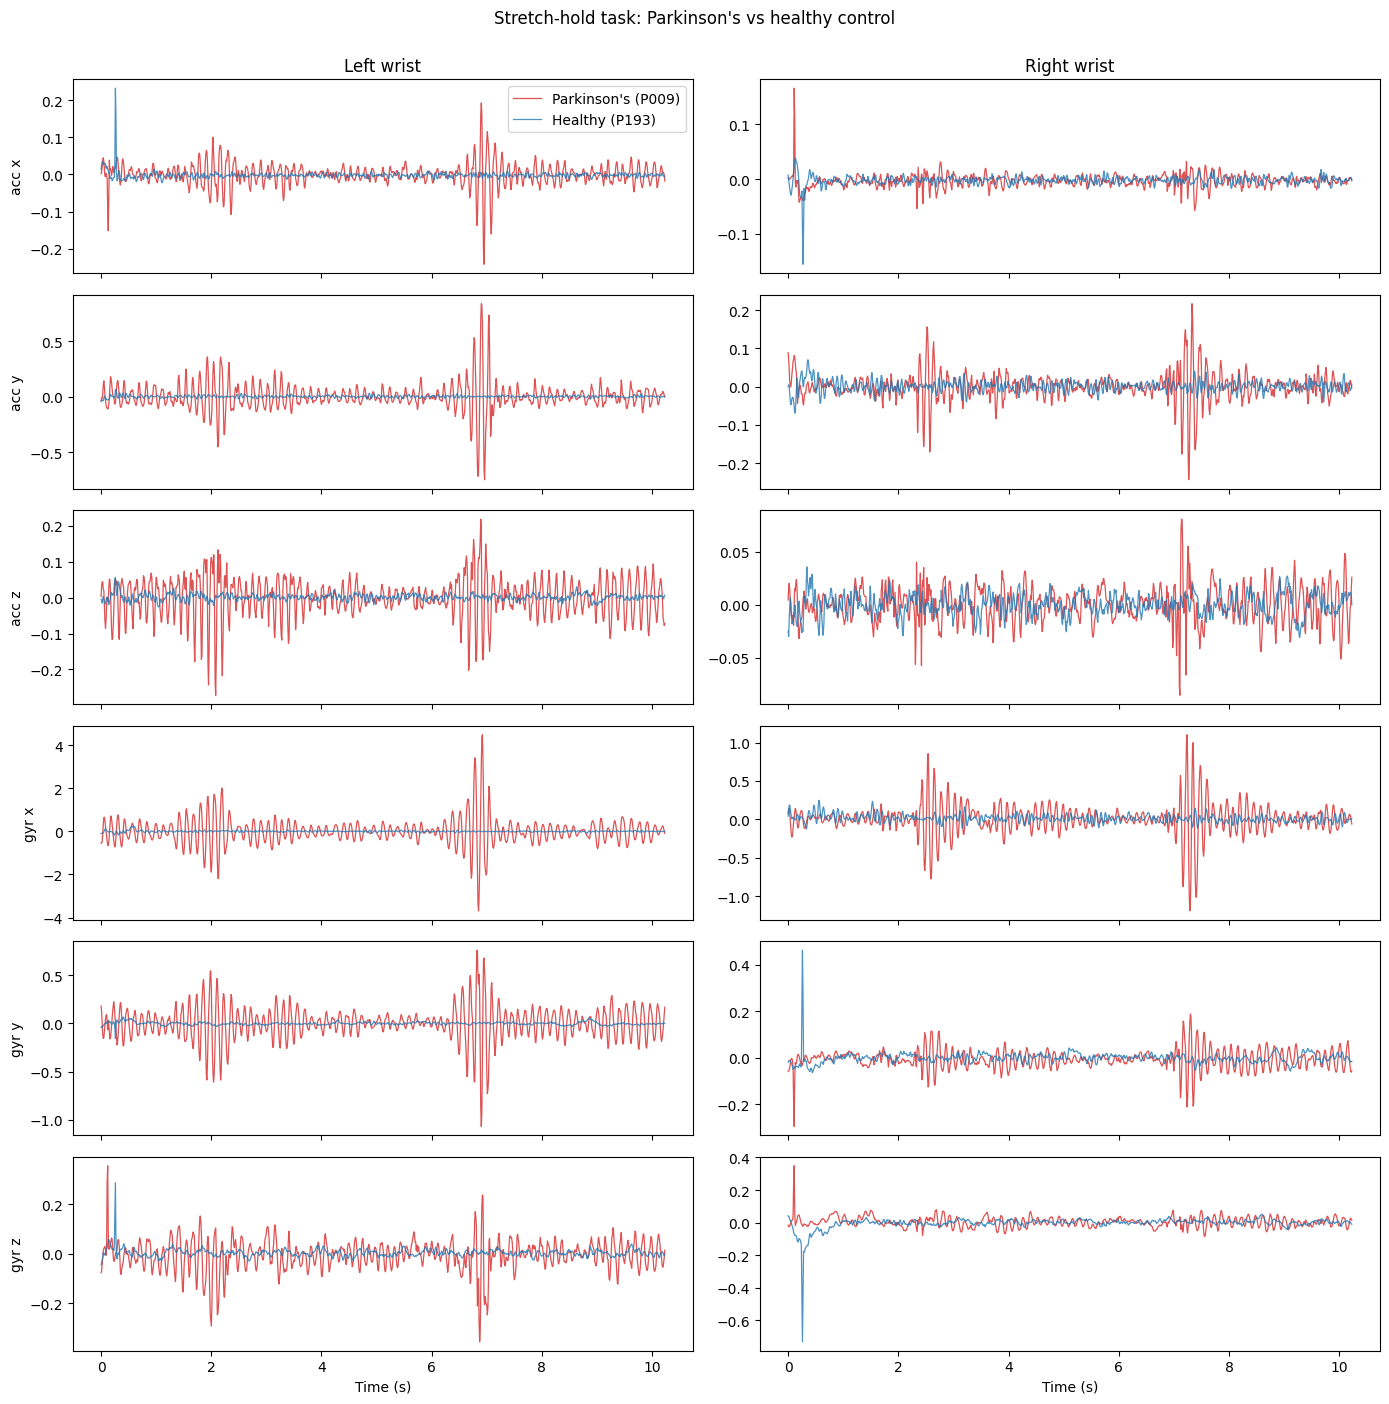

In [10]:
#This chart represent the healthy vs Parkinson's raw movement sdata over a 10.24 timeseries
#There are 6 channels to repredent the movement in linear x,y,z planes and rotational x,y,z planes

fs = 100                      # Hz (1024 samples over 10.24 s)
t = np.arange(1024) / fs
channels = ['acc x', 'acc y', 'acc z', 'gyr x', 'gyr y', 'gyr z']

# Edit the variable names to the dataframes
data = {
    ('Parkinson\'s (P009)', 'Left'):  df_009stretchhold_left,
    ('Parkinson\'s (P009)', 'Right'): df_009stretchhold_right,
    ('Healthy (P193)', 'Left'):       df_193stretchhold_left,
    ('Healthy (P193)', 'Right'):      df_193stretchhold_right,
}
colors = {'Parkinson\'s (P009)': 'tab:red', 'Healthy (P193)': 'tab:blue'}

# Raw time series: one row per channel, one column per wrist
fig, axes = plt.subplots(6, 2, figsize=(14, 14), sharex=True)
for col, side in enumerate(['Left', 'Right']):
    for row, ch in enumerate(channels):
        ax = axes[row, col]
        for group in colors:
            ax.plot(t, data[(group, side)][ch], color=colors[group],
                    alpha=0.8, lw=0.9, label=group)
        if col == 0:
            ax.set_ylabel(ch)
        if row == 0:
            ax.set_title(f'{side} wrist')
axes[-1, 0].set_xlabel('Time (s)')
axes[-1, 1].set_xlabel('Time (s)')
axes[0, 0].legend(loc='upper right')
fig.suptitle('Stretch-hold task: Parkinson\'s vs healthy control', y=1.0)
plt.tight_layout()
plt.show()

Severity (left):  8.05
Severity (right): 4.49
Severity (mean):  6.27
Duration: 12 y  ->  progression index: 0.52 per year


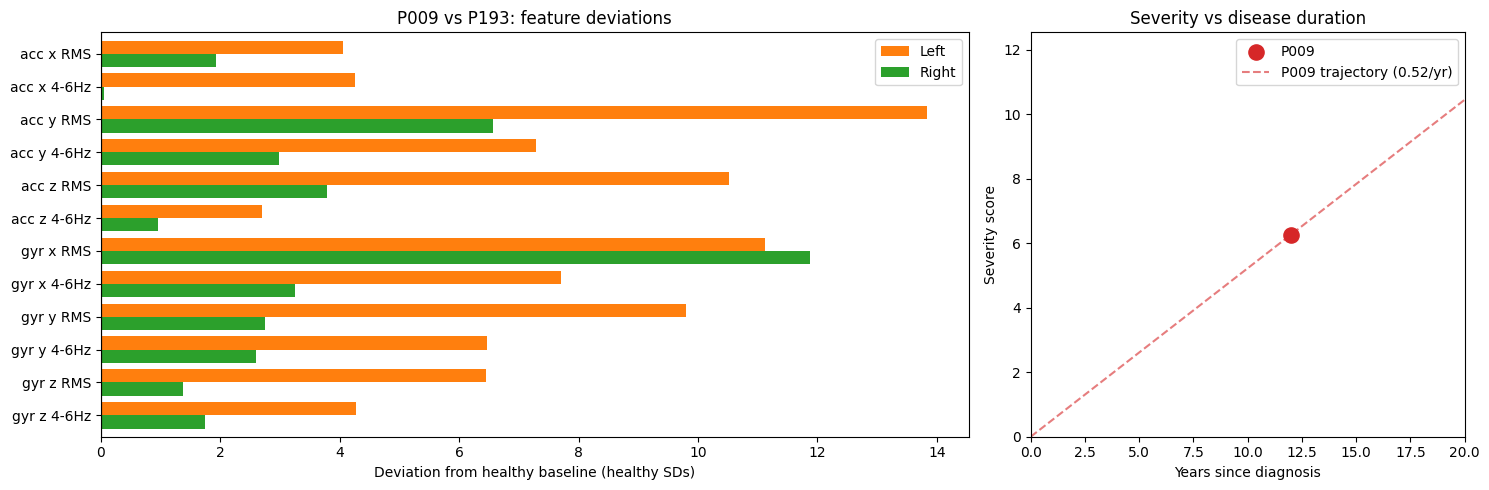

In [18]:
#This cell goes through creating a standard movement signature based on the healthy control to see how far the Parkinson's movement deviates
#from the healthy

fs = 100
channels = ['acc x', 'acc y', 'acc z', 'gyr x', 'gyr y', 'gyr z']

# RMS was found to reprensent an SD (to suggest how “big” is the movement overall)
# and 4-6 Hz was found to represents how much of the movement sits in the tremor range (4-6Hz is the classic Parkinsonian tremor)
#Since it is based on one healthy control, the 10.24 was separated in 13 different 2.56s overlapping bins and treated as independent windows

def window_features(df, win=256, step=64):
    rows = []
    for start in range(0, len(df) - win + 1, step):
        seg = df[channels].iloc[start:start + win].values
        seg = seg - seg.mean(axis=0)                     # remove gravity/DC offset
        row = {}
        for i, ch in enumerate(channels):
            x = seg[:, i]
            f, p = welch(x, fs=fs, nperseg=win)
            band = (f >= 4) & (f <= 6)
            row[f'{ch} RMS'] = np.log10(np.sqrt(np.mean(x**2)) + 1e-12)
            row[f'{ch} 4-6Hz'] = np.log10(p[band].sum() * (f[1] - f[0]) + 1e-12)
        rows.append(row)
    return pd.DataFrame(rows)

#Severity index: how many "healthy SDs" does the Parkinsons patient sits from the healthy
SD_FLOOR = 0.05   # log10 units; stops tiny healthy variance from inflating z

def severity(pd_df, hc_df):
    f_pd, f_hc = window_features(pd_df), window_features(hc_df)
    mu = f_hc.mean()
    sd = f_hc.std(ddof=1).clip(lower=SD_FLOOR)
    z = (f_pd.mean() - mu) / sd
    return np.sqrt((z**2).mean()), z

sev_left,  z_left  = severity(df_009stretchhold_left,  df_193stretchhold_left)
sev_right, z_right = severity(df_009stretchhold_right, df_193stretchhold_right)
severity_score = (sev_left + sev_right) / 2

#Considering disease duration
age_dx, age_now = 35, 47
duration = age_now - age_dx                              # 12 years as per df_ptdemo
progression_index = severity_score / duration            # severity units per year

print(f"Severity (left):  {sev_left:.2f}")
print(f"Severity (right): {sev_right:.2f}")
print(f"Severity (mean):  {severity_score:.2f}")
print(f"Duration: {duration} y  ->  progression index: {progression_index:.2f} per year")

# --- 4. Figures ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [2, 1]})

# (a) which features (RMS or 4-6Hz per channel) drive the score
zdf = pd.DataFrame({'Left': z_left, 'Right': z_right})
zdf.plot.barh(ax=axes[0], color=['tab:orange', 'tab:green'], width=0.8)
axes[0].axvline(0, color='k', lw=0.8)
axes[0].set_xlabel('Deviation from healthy baseline (healthy SDs)')
axes[0].set_title('P009 vs P193: feature deviations')
axes[0].invert_yaxis()

# (b) severity vs time since diagnosis
ax = axes[1]
ax.scatter(duration, severity_score, s=120, color='tab:red', zorder=3, label='P009')
x = np.linspace(0, 20, 50)
ax.plot(x, progression_index * x, '--', color='tab:red', alpha=0.6,
        label=f'P009 trajectory ({progression_index:.2f}/yr)')
ax.set_xlim(0, 20); ax.set_ylim(0, severity_score * 2)
ax.set_xlabel('Years since diagnosis'); ax.set_ylabel('Severity score')
ax.set_title('Severity vs disease duration')
ax.legend()
plt.tight_layout()
plt.show()